# Accident Severity Flagger for UK Road Safety Officers
**Academic Project Notebook — Project-I (Semester 1)**  
**Student Name**: Kunche Abhishek  

---
## 📌 Overview
This interactive Jupyter Notebook contains the complete end-to-end data science pipeline:
1. **STATS19 Data Loading & Categorical Decoding** (101,525 DfT collision records).
2. **Exploratory Data Analysis (EDA) & Visualizations** (Matplotlib & Seaborn).
3. **Mathematics of Probability & Statistical Independence** ($\chi^2$ test, Cramér's V, Bayesian conditional risk).
4. **Machine Learning Classifiers & Baselines** (Logistic Regression, Decision Tree, Bagging, AdaBoost, Naive Bayes).
5. **Budget-Constrained Evaluation** ($\text{Precision@K}$, $\text{Recall@K}$, Bootstrapped 95% CIs).
6. **Council Prioritized Shortlist** & **SHAP Feature Explainability**.

### ⚙️ Step 0: Import Libraries & Environment Setup

In [1]:
import sys
import os
import logging

# Ensure project root (containing 'src' and STATS19 dataset) is in sys.path & cwd
project_root = os.path.abspath(".")
if not os.path.exists(os.path.join(project_root, "src")):
    for candidate in [os.path.abspath(".."), os.path.abspath("../..")]:
        if os.path.exists(os.path.join(candidate, "src")):
            project_root = candidate
            os.chdir(project_root)
            break

if project_root not in sys.path:
    sys.path.insert(0, project_root)

# Prevent missing Helvetica font warning spam on Windows
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Set plot style with cross-platform fallback fonts
sns.set_theme(style="darkgrid")
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial", "Helvetica", "sans-serif"]
plt.rcParams["figure.figsize"] = (10, 5)
print("✓ Environment Initialized Successfully.")

✓ Environment Initialized Successfully.


---
## 1️⃣ STATS19 Categorical Decoding & Data Loading

In [2]:
from src.decoder import Stats19Decoder

data_path = "dft-road-casualty-statistics-collision-2025.csv"
if not os.path.exists(data_path):
    candidate = os.path.join(project_root, data_path)
    if os.path.exists(candidate):
        data_path = candidate
if not os.path.exists(data_path):
    raise FileNotFoundError(f"STATS19 dataset not found at '{data_path}'.")

decoder = Stats19Decoder(data_path)
decoded_df = decoder.decode()
clean_df = decoder.get_clean_features_df()

print(f"Total Collision Records: {len(decoded_df):,}")
print(f"Severe Collision Proportion: {clean_df['is_severe'].mean() * 100:.2f}%")
clean_df.head()

Total Collision Records: 101,525
Severe Collision Proportion: 26.24%


,collision_index,collision_severity,is_severe,severity_label,weather_conditions,weather_label,light_conditions,light_label,road_type,road_type_label,junction_detail,junction_label,speed_limit,number_of_vehicles,number_of_casualties
0,202517H102225,2,1,Serious,1,Fine no high winds,1,Daylight,3,Dual carriageway,-1,Data missing or out of range,40,3,3
1,2.02507E+12,3,0,Slight,5,Raining + high winds,4,Darkness - lights lit,2,One way street,13,T or staggered junction,30,2,2
2,2.02507E+12,2,1,Serious,9,Unknown,7,Darkness - lighting unknown,6,Single carriageway,16,Mini-roundabout or crossroads,30,2,1
3,2.02504E+12,2,1,Serious,1,Fine no high winds,4,Darkness - lights lit,6,Single carriageway,0,Not at junction or within 20 metres,30,1,1
4,2.02516E+12,3,0,Slight,1,Fine no high winds,1,Daylight,6,Single carriageway,0,Not at junction or within 20 metres,30,2,1


---
## 2️⃣ Exploratory Data Analysis (EDA) & Data Visualizations

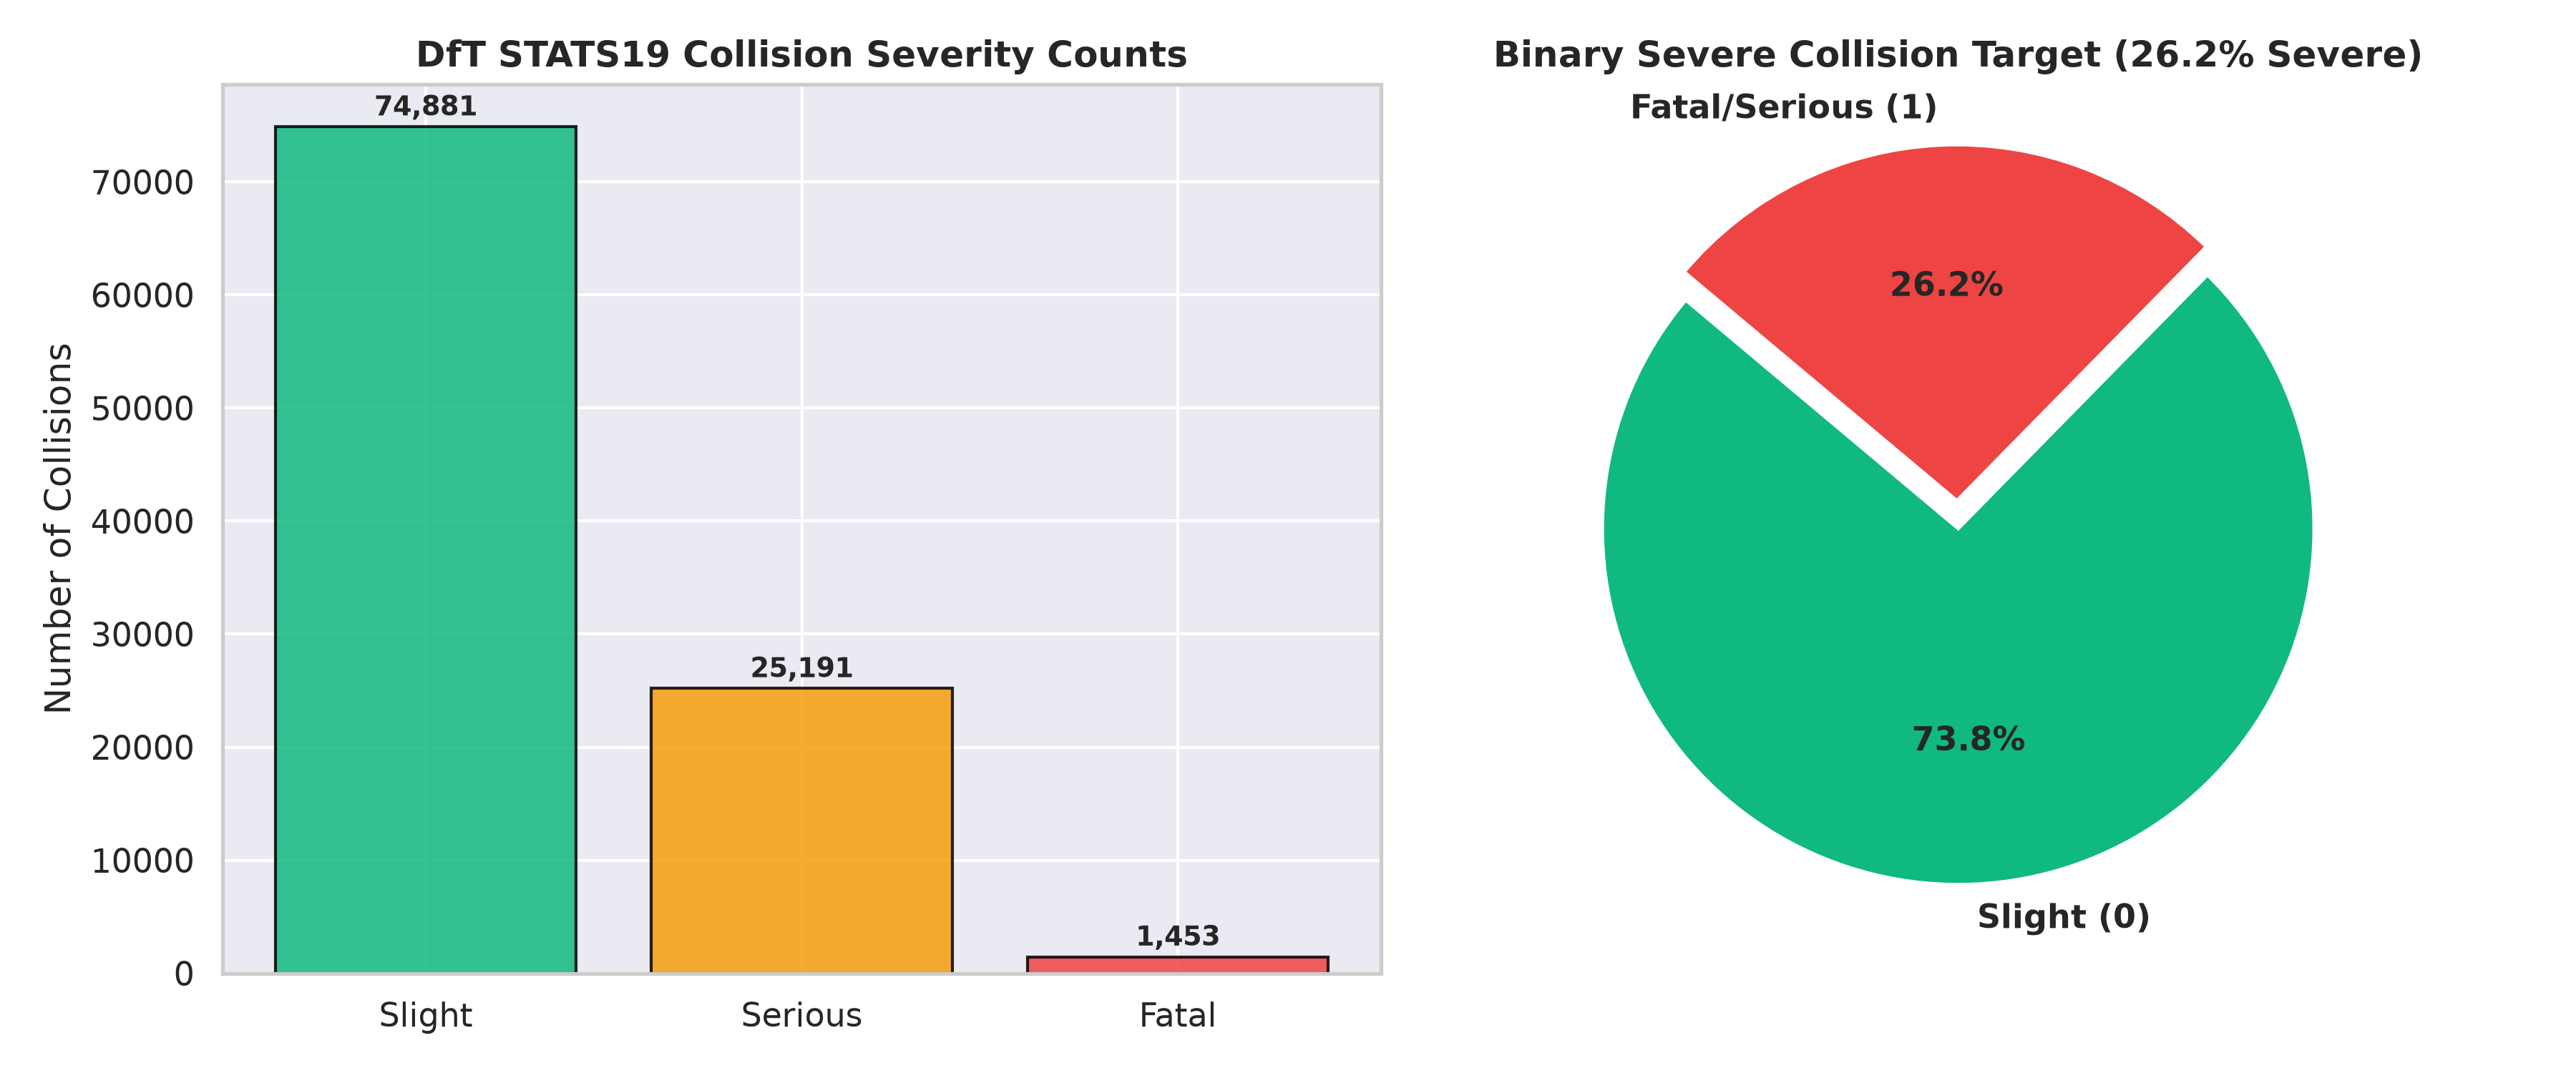

In [3]:
from src.visualization import DataVisualizationEngine

viz = DataVisualizationEngine(decoded_df)
# Override Helvetica-only setting from DataVisualizationEngine for cross-platform rendering
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial", "Helvetica", "sans-serif"]

# 1. Plot Severity Target Distribution & display inline
severity_chart_path = viz.plot_severity_distribution()
try:
    from IPython.display import Image, display
    display(Image(filename=severity_chart_path))
except ImportError:
    print(f"Chart saved to: {severity_chart_path}")

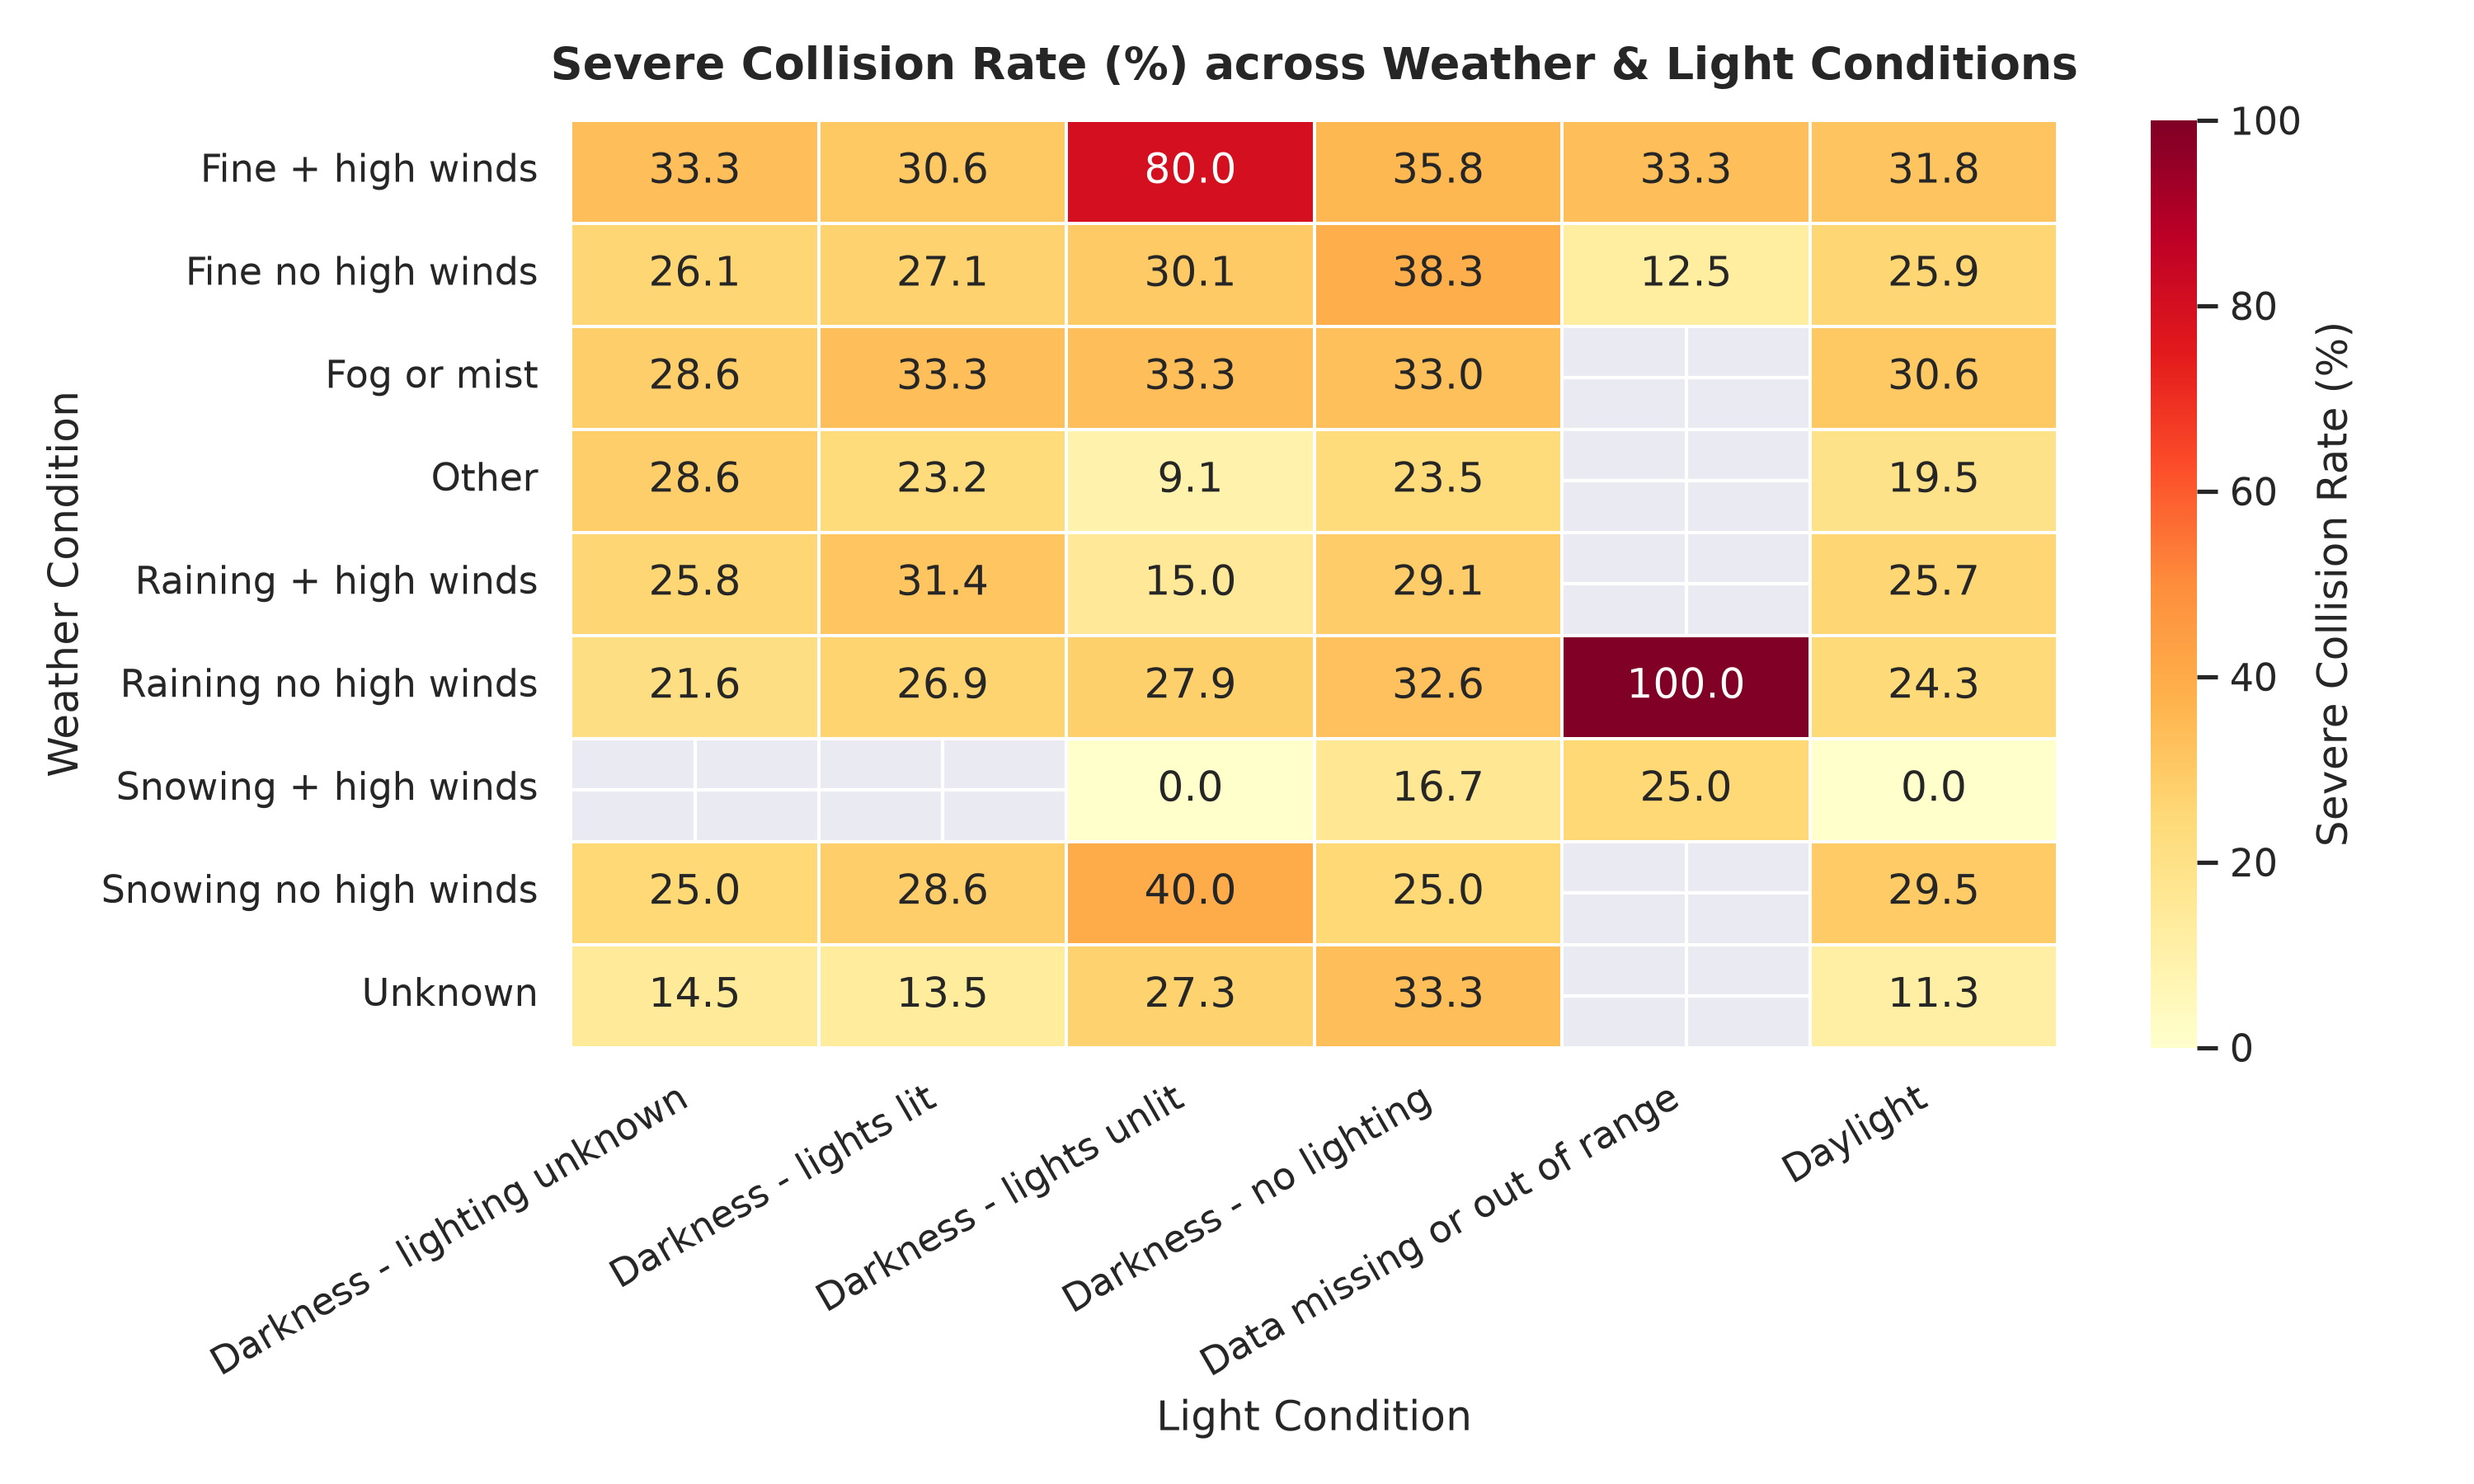

In [4]:
# 2. Weather vs. Light Severe Risk Heatmap
heatmap_chart_path = viz.plot_weather_light_risk_heatmap()
try:
    from IPython.display import Image, display
    display(Image(filename=heatmap_chart_path))
except ImportError:
    print(f"Chart saved to: {heatmap_chart_path}")

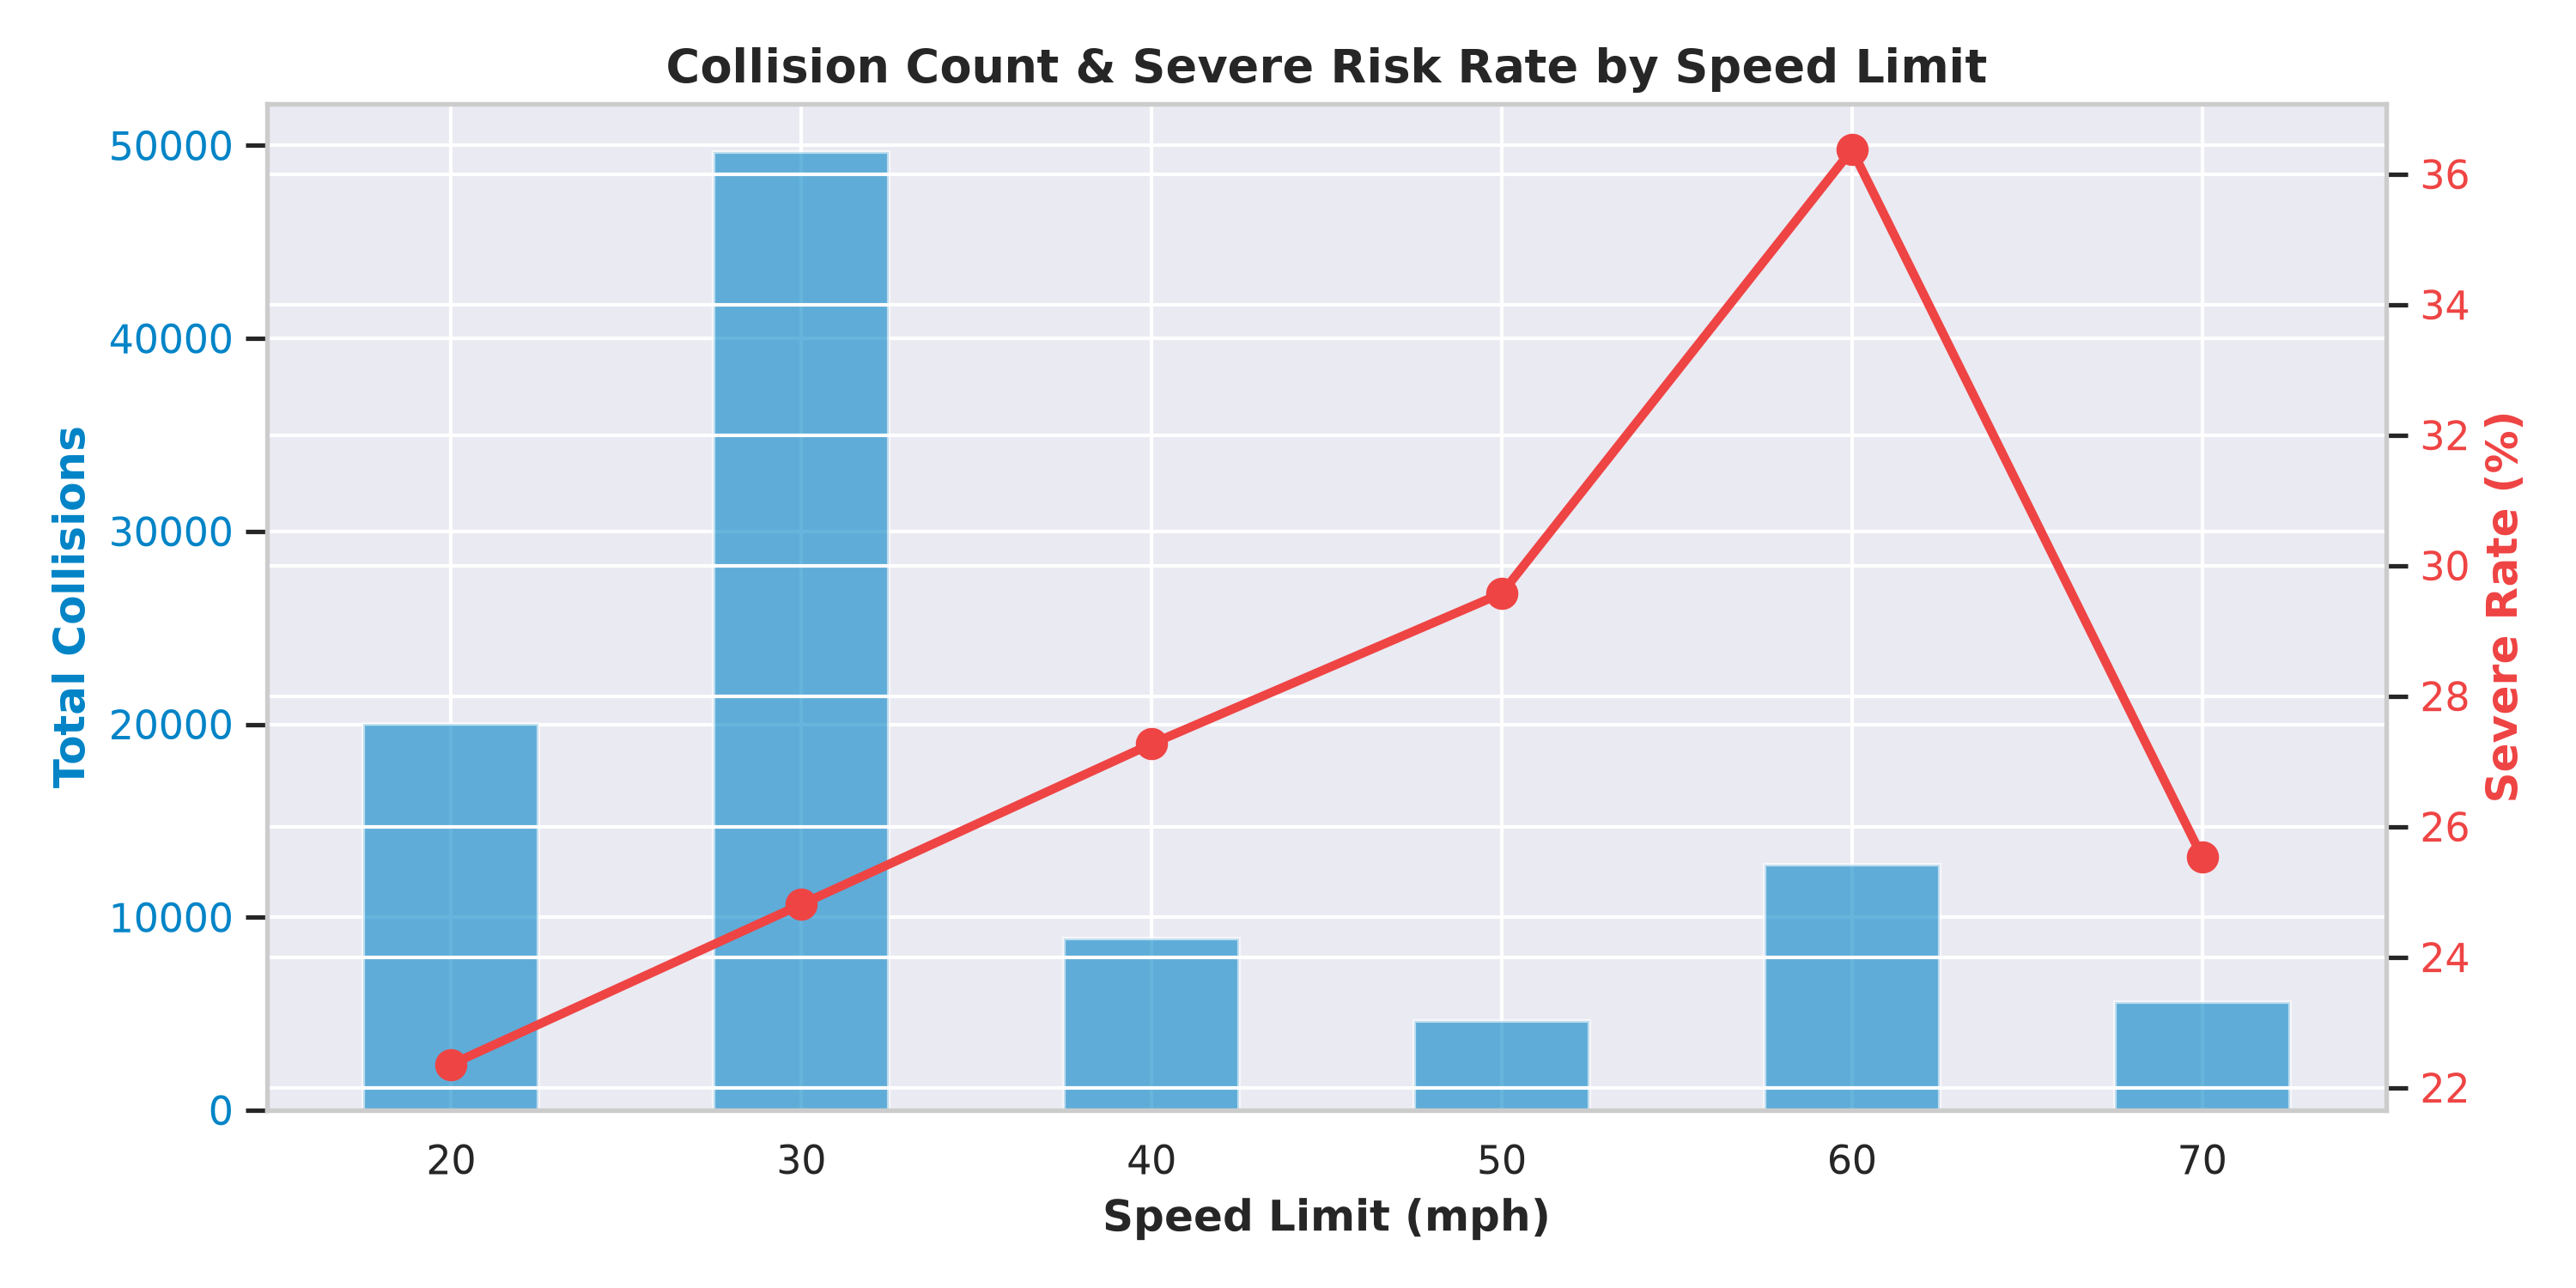

In [5]:
# 3. Speed Limit Collision & Severe Risk Rate Distribution
speed_chart_path = viz.plot_speed_limit_risk_distribution()
try:
    from IPython.display import Image, display
    display(Image(filename=speed_chart_path))
except ImportError:
    print(f"Chart saved to: {speed_chart_path}")

---
## 3️⃣ Mathematics of Probability & Statistical Independence ($\chi^2$ & Cramér's V)

In [6]:
from src.statistical_analysis import run_full_statistical_analysis

stats_report = run_full_statistical_analysis(clean_df)

chi_rows = []
for key, label in [
    ("weather_conditions", "Weather Conditions"),
    ("light_conditions", "Light Conditions"),
    ("road_type", "Road Type"),
    ("junction_detail", "Junction Detail"),
]:
    t = stats_report["tests"][key]
    print(
        f"{label:<18}: Chi2 = {t['chi2_statistic']:<8} | p = {t['p_value_formatted']:<8} | "
        f"df = {t['degrees_of_freedom']:<2} | Cramér V = {t['cramers_v']}"
    )
    chi_rows.append({
        "Factor": label,
        "Chi2 Statistic": t["chi2_statistic"],
        "p-value": t["p_value_formatted"],
        "df": t["degrees_of_freedom"],
        "Cramér's V": t["cramers_v"],
        "Effect Size": t["effect_size"],
        "Significant (p < 0.05)": t["is_statistically_significant"],
    })

pd.DataFrame(chi_rows)

Weather Conditions: Chi2 = 321.548  | p = < 0.0001 | df = 8  | Cramér V = 0.0563
Light Conditions  : Chi2 = 340.381  | p = < 0.0001 | df = 4  | Cramér V = 0.0579
Road Type         : Chi2 = 607.1315 | p = < 0.0001 | df = 5  | Cramér V = 0.0773
Junction Detail   : Chi2 = 448.1555 | p = < 0.0001 | df = 6  | Cramér V = 0.0687


,Factor,Chi2 Statistic,p-value,df,Cramér's V,Effect Size,Significant (p < 0.05)
0,Weather Conditions,321.5480,< 0.0001,8,0.0563,Negligible / Weak,True
1,Light Conditions,340.3810,< 0.0001,4,0.0579,Negligible / Weak,True
2,Road Type,607.1315,< 0.0001,5,0.0773,Negligible / Weak,True
3,Junction Detail,448.1555,< 0.0001,6,0.0687,Negligible / Weak,True


---
## 4️⃣ Machine Learning Models & Bootstrapped Precision@K Evaluation

In [7]:
import joblib
from src.model_trainer import AccidentSeverityModelTrainer

trainer = AccidentSeverityModelTrainer(data_path)
# Threading backend prevents Windows Jupyter multiprocessing hangs in BaggingClassifier(n_jobs=-1)
with joblib.parallel_backend("threading", n_jobs=1):
    results = trainer.train_and_evaluate_all()
trainer.save_artifacts("models_saved")

# Build Summary DataFrame
summary_rows = []
for model_name, res in results.items():
    p25 = res["metrics_at_k"]["K_25"]
    summary_rows.append({
        "Model Name": model_name,
        "ROC-AUC": res["roc_auc"],
        "Precision@25 (%)": p25["precision_at_k_percent"],
        "Precision@25 95% CI": f"[{p25['precision_at_k_ci95'][0]}, {p25['precision_at_k_ci95'][1]}]",
        "Recall@25 (%)": p25["recall_at_k_percent"],
        "Accuracy (%)": round(res["accuracy"] * 100, 2)
    })

df_summary = pd.DataFrame(summary_rows)
df_summary

Saved preprocessor and 5 models to models_saved/


,Model Name,ROC-AUC,Precision@25 (%),Precision@25 95% CI,Recall@25 (%),Accuracy (%)
0,Baseline 1: Majority Class,0.5000,44.0,"[0.08, 0.441]",0.21,73.76
1,Baseline 2: Group-By Road Type,0.5415,32.0,"[0.12, 0.48]",0.15,41.82
2,Logistic Regression,0.5881,32.0,"[0.16, 0.56]",0.15,54.27
3,Decision Tree,0.5801,20.0,"[0.08, 0.4]",0.09,63.31
4,Bagging Classifier,0.5834,36.0,"[0.12, 0.48]",0.17,63.03
5,AdaBoost Classifier,0.5679,40.0,"[0.199, 0.56]",0.19,73.76
6,Naive Bayes,0.5747,24.0,"[0.159, 0.52]",0.11,38.04


---
## 5️⃣ Council Top-K Prioritized Interventions Shortlist

In [8]:
from src.probabilistic_engine import ProbabilisticRiskEngine

engine = ProbabilisticRiskEngine(decoded_df)
shortlist = engine.generate_prioritized_shortlist(top_k=15)
df_shortlist = pd.DataFrame(shortlist)
df_shortlist

,rank,road_type,weather_condition,light_condition,speed_limit,total_collisions,severe_collisions,severe_risk_rate_percent,risk_multiplier
0,1,Dual carriageway,Raining + high winds,Darkness - lights lit,30 mph,15,9,60.00,2.29
1,2,Dual carriageway,Fine no high winds,Darkness - no lighting,60 mph,31,18,58.06,2.21
2,3,Single carriageway,Fine no high winds,Darkness - lights unlit,60 mph,32,16,50.00,1.91
3,4,Single carriageway,Raining + high winds,Darkness - lights lit,20 mph,40,19,47.50,1.81
4,5,Single carriageway,Snowing no high winds,Darkness - lights lit,30 mph,28,13,46.43,1.77
5,6,Single carriageway,Fine no high winds,Darkness - lighting unknown,50 mph,26,12,46.15,1.76
6,7,Dual carriageway,Fine no high winds,Darkness - no lighting,40 mph,18,8,44.44,1.69
7,8,Single carriageway,Fine no high winds,Darkness - no lighting,50 mph,366,156,42.62,1.62
8,9,Single carriageway,Fine no high winds,Darkness - no lighting,60 mph,2034,852,41.89,1.60
9,10,Single carriageway,Fine + high winds,Darkness - lights lit,20 mph,34,14,41.18,1.57


---
## 6️⃣ SHAP Feature Explainability & Attribution Analysis

In [9]:
import joblib
from src.explainability import ExplainabilityEngine

# Reuse trained model from Step 4, or load serialized artifacts if cell is run standalone
if "trainer" in globals() and getattr(trainer, "trained_models", None):
    best_model = trainer.trained_models["Logistic Regression"]
    preprocessor = trainer.preprocessor
else:
    preprocessor = joblib.load("models_saved/preprocessor.joblib")
    best_model = joblib.load("models_saved/logistic_regression.joblib")

explainer = ExplainabilityEngine(preprocessor, best_model)

high_risk_query = {
    "road_type": 6,             # Single carriageway
    "weather_conditions": 5,    # Raining + high winds
    "light_conditions": 6,      # Darkness - no lighting
    "junction_detail": 0,       # Not at junction or within 20 metres
    "speed_limit": 60           # 60 mph
}

contributions = explainer.explain_prediction(high_risk_query)
df_contributions = pd.DataFrame(contributions)
print("Top Risk Factor Attributions (Single Carriageway, Raining + High Winds, Darkness Unlit, 60 mph):")
df_contributions[["feature", "risk_direction", "formatted_impact", "impact_score"]]

Top Risk Factor Attributions (Single Carriageway, Raining + High Winds, Darkness Unlit, 60 mph):


,feature,risk_direction,formatted_impact,impact_score
0,Road Type (Code 6),Increases Risk,+0.33,0.3260
1,Speed Limit (60 mph),Increases Risk,+0.25,0.2498
2,Junction Type (Code 0),Increases Risk,+0.20,0.1976
3,Weather Condition (Code 5),Increases Risk,+0.09,0.0948
4,Light Condition (Code 6),Increases Risk,+0.09,0.0874
